In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Covid-19 Twitter Dataset (Apr-Jun 2020).csv to Covid-19 Twitter Dataset (Apr-Jun 2020).csv


In [ ]:
!pip install nltk seaborn plotly tensorflow


In [ ]:
import pandas as pd
import numpy as np
import re

import nltk
nltk.download('stopwords')
nltk.download('wordnet')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [ ]:
df = pd.read_csv("Covid-19 Twitter Dataset (Apr-Jun 2020).csv")

df = df[['clean_tweet', 'sentiment', 'created_at']]
df.dropna(inplace=True)

print(df.head())
print("Total tweets:", len(df))


                                         clean_tweet sentiment  created_at
0  call leader help protect refuge covid19 provid...       pos  2020-04-19
1  ogun state support cbn nirsal covid19 target c...       pos  2020-04-19
2  polic offici base namahadi polic station busi ...       pos  2020-04-19
3                   covid19 oyo discharg two patient       neu  2020-04-19
4                               condol famili surviv       neu  2020-04-19
Total tweets: 143419


In [ ]:
label_encoder = LabelEncoder()
df['sentiment_label'] = label_encoder.fit_transform(df['sentiment'])



In [ ]:
MAX_WORDS = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS)
tokenizer.fit_on_texts(df['clean_tweet'])

sequences = tokenizer.texts_to_sequences(df['clean_tweet'])
X = pad_sequences(sequences, maxlen=MAX_LEN)

y = df['sentiment_label']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
model = Sequential([
    Embedding(MAX_WORDS, 128),
    LSTM(128),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
1435/1435 ━━━━━━━━━━━━━━━━━━━━ 369s 255ms/step - accuracy: 0.8216 - loss: 0.4242 - val_accuracy: 0.9779 - val_loss: 0.0897
Epoch 2/5
1435/1435 ━━━━━━━━━━━━━━━━━━━━ 381s 265ms/step - accuracy: 0.9830 - loss: 0.0703 - val_accuracy: 0.9791 - val_loss: 0.0793
Epoch 3/5
1435/1435 ━━━━━━━━━━━━━━━━━━━━ 383s 267ms/step - accuracy: 0.9872 - loss: 0.0539 - val_accuracy: 0.9816 - val_loss: 0.0729
Epoch 4/5
1435/1435 ━━━━━━━━━━━━━━━━━━━━ 382s 266ms/step - accuracy: 0.9891 - loss: 0.0426 - val_accuracy: 0.9817 - val_loss: 0.0703
Epoch 5/5
1435/1435 ━━━━━━━━━━━━━━━━━━━━ 367s 255ms/step - accuracy: 0.9915 - loss: 0.0330 - val_accuracy: 0.9821 - val_loss: 0.0747


In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Sentiment Accuracy:", round(accuracy * 100, 2), "%")


897/897 ━━━━━━━━━━━━━━━━━━━━ 50s 56ms/step - accuracy: 0.9811 - loss: 0.0746
Sentiment Accuracy: 98.1 %


In [ ]:
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_tfidf = tfidf.fit_transform(df['clean_tweet'])

lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X_tfidf)

feature_names = tfidf.get_feature_names_out()

def display_topics(model, words, n=10):
    for i, topic in enumerate(model.components_):
        print(f"\nTopic {i+1}:")
        print(" ".join([words[j] for j in topic.argsort()[:-n-1:-1]]))

display_topics(lda, feature_names)



Topic 1:
case covid19 new death updat report total number confirm test

Topic 2:
covid19 peopl know trump like home mask think say stay

Topic 3:
covid19 pandem vaccin china impact crisi world respons develop countri

Topic 4:
covid19 test patient death posit hospit die peopl rate case

Topic 5:
covid19 support help health pandem join fight worker thank work


In [ ]:
misinfo_keywords = [
    "fake", "hoax", "myth", "rumor", "5g",
    "conspiracy", "plandemic", "bioweapon",
    "garlic", "home remedy"
]

def detect_misinformation(text):
    return any(word in text.lower() for word in misinfo_keywords)

df['misinformation'] = df['clean_tweet'].apply(detect_misinformation)


In [ ]:
df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')

sentiment_trend = df.groupby(df['created_at'].dt.date)['sentiment_label'].mean()
misinfo_trend = df[df['misinformation']].groupby(df['created_at'].dt.date).size()


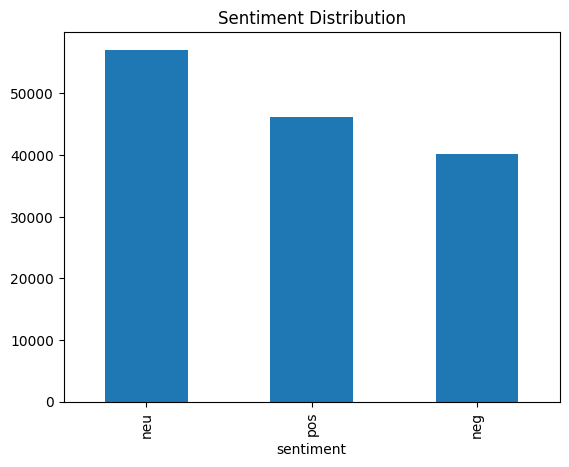

In [ ]:
df['sentiment'].value_counts().plot(kind='bar')
plt.title("Sentiment Distribution")
plt.show()


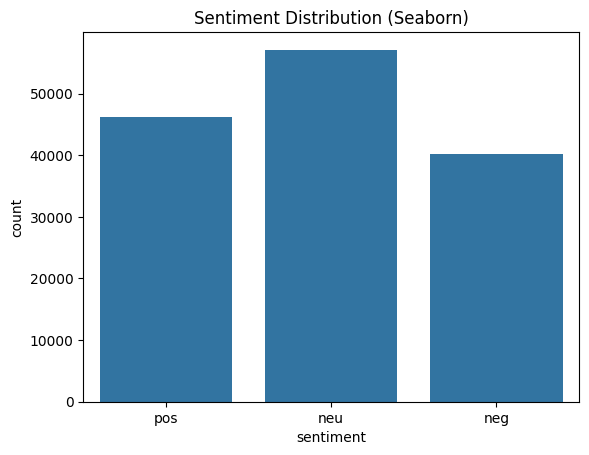

In [ ]:
sns.countplot(x='sentiment', data=df)
plt.title("Sentiment Distribution (Seaborn)")
plt.show()


In [ ]:
fig = px.line(
    sentiment_trend.reset_index(),
    x='created_at',
    y='sentiment_label',
    title="Average Sentiment Trend Over Time"
)
fig.show()


In [ ]:
def predict_sentiment(text):
    seq = tokenizer.texts_to_sequences([text.lower()])
    padded = pad_sequences(seq, maxlen=MAX_LEN)
    pred = model.predict(padded)
    return label_encoder.inverse_transform([pred.argmax()])[0]

def predict_misinformation(text):
    return "Misinformation Detected" if detect_misinformation(text) else "No Misinformation"

# TEST
user_text = "5G towers spread COVID and vaccines are fake"

print("Input:", user_text)
print("Sentiment:", predict_sentiment(user_text))
print("Misinformation:", predict_misinformation(user_text))


Input: 5G towers spread COVID and vaccines are fake
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 658ms/step
Sentiment: neg
Misinformation: Misinformation Detected
